# Customer Segmentation using Machine Learning

This notebook groups mall customers into 5 distinct segments using K-Means Clustering.

**Tools used:** Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn · Jupyter Notebook

| Step | Description | Status |
| :---: | :--- | :---: |
| 1 | Dataset Loading | ✅ |
| 2 | Data Cleaning | ✅ |
| 3 | Exploratory Data Analysis (EDA) | ✅ |
| 4 | Feature Selection | ✅ |
| 5 | Feature Scaling (StandardScaler) | ✅ |
| 6 | K-Means Clustering — Elbow Method | ✅ |
| 7 | Cluster Analysis & Customer Profiling | ✅ |
| 8 | Cluster Visualizations | ✅ |
| 9 | Conclusion & Portfolio Documentation | ✅ |

## Step 1: Load the dataset

The file is `Mall_Customers.csv`. It was already on this computer. We copied it into the `dataset` folder. We did not download a new file.

In [1]:
# Import the library we need to read a table of data
import pandas as pd

# Read the CSV file. The notebook lives in the notebooks folder,
# so we go up one folder and then into dataset.
df = pd.read_csv("../dataset/Mall_Customers.csv")

# Show the first 5 rows so we can see what the data looks like
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Step 2: Check the data

Before we make charts or groups, we check:

1. How many rows and columns are there?
2. What are the column names?
3. What type of data is in each column?
4. Are any values missing?
5. Are any rows repeated?

In [2]:
# shape gives (number of rows, number of columns)
print("Number of rows and columns:")
print(df.shape)

# columns shows the names exactly as they appear in the file
print("\nColumn names:")
print(df.columns.tolist())

Number of rows and columns:
(200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [3]:
# dtypes shows the kind of value in each column
# int64 means a whole number
# object (or str in newer pandas versions) means text
print("Data types:")
print(df.dtypes)

Data types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [4]:
# Count empty cells in each column
# 0 means that column has no missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [5]:
# duplicated() marks a row as True when the same row already appeared
# sum() counts how many True values we have
duplicate_rows = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

# Also check the customer id, because each customer should appear only once
duplicate_ids = df["CustomerID"].duplicated().sum()
print("Number of duplicate CustomerID values:", duplicate_ids)

Number of duplicate rows: 0
Number of duplicate CustomerID values: 0


## Cleaning result

The file has **200 rows** and **5 columns**:

- `CustomerID` — a number that identifies each customer
- `Gender` — text: Male or Female
- `Age` — whole number
- `Annual Income (k$)` — yearly income in thousands of dollars
- `Spending Score (1-100)` — a score of how much the customer spends at the mall

There are **0 missing values** and **0 duplicate rows**. Every `CustomerID` is unique.

We do not delete or fill any values, because the data is already clean. We keep all 200 customers for the next step.

## Step 3: Exploratory Data Analysis

We use the same `df` table from the cleaning step. We do not change the CSV file.

First we look at the three number columns:

- `Age`
- `Annual Income (k$)`
- `Spending Score (1-100)`

In [6]:
# These three columns are numbers, so we can calculate averages
number_columns = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

# describe() shows count, average, spread, and the smallest and largest values
# This line only reads the data. It does not change df or the CSV file.
df[number_columns].describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### What the statistics say

Each column has **200** values, so nobody is missing from this summary.

- **Age:** the average is about **39**. The youngest customer is **18** and the oldest is **70**. Half of the customers are **36 or younger**.
- **Annual income:** the average is about **61**, which means about $61,000 a year. Income goes from **15** to **137**.
- **Spending score:** the average is about **50**. Scores run from **1** to **99**, so some customers spend very little and some spend a lot.

Income and spending are both spread out. Customers are not all the same, which is why grouping them can help a shop.

In [7]:
# Libraries for simple charts
import matplotlib.pyplot as plt
import seaborn as sns

# A light grid makes the charts easier to read
sns.set_theme(style="whitegrid")

### Histograms

A histogram shows how many customers fall into each range. A tall bar means many customers are in that range.

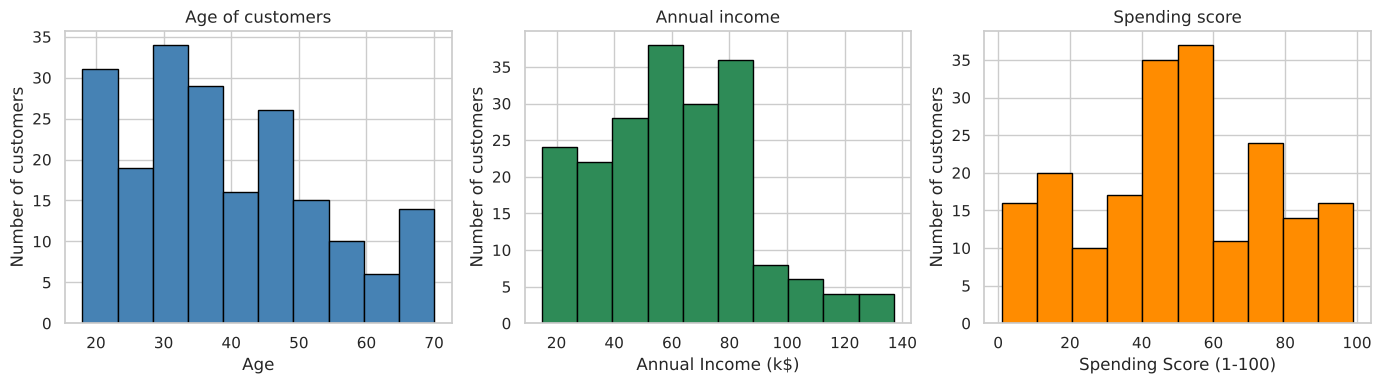

In [8]:
# Three histograms side by side: age, income, and spending score
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(df["Age"], bins=10, color="steelblue", edgecolor="black")
axes[0].set_title("Age of customers")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of customers")

axes[1].hist(df["Annual Income (k$)"], bins=10, color="seagreen", edgecolor="black")
axes[1].set_title("Annual income")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Number of customers")

axes[2].hist(df["Spending Score (1-100)"], bins=10, color="darkorange", edgecolor="black")
axes[2].set_title("Spending score")
axes[2].set_xlabel("Spending Score (1-100)")
axes[2].set_ylabel("Number of customers")

plt.tight_layout()

# Save the chart. This does not change the original dataset.
plt.savefig("../outputs/01_histograms.png", dpi=120)
plt.show()

**How to read these histograms**

- **Age:** the tallest bars are young adults and people around 30 to 40. Fewer customers are in their 50s and 60s. A small group is close to 70.
- **Income:** most customers earn roughly between 40 and 80 (thousands of dollars). The tallest bar is around 60 to 70. Very high incomes, above 100, are rare.
- **Spending score:** the tallest bars are around 40 to 60. There are also smaller groups with very low scores and very high scores. One spending level does not describe everyone.

A shop cannot treat all of these customers the same way.

### Box plots

A box plot shows the middle of the data and any values that sit far away from the rest. The line inside the box is the middle value (the median).

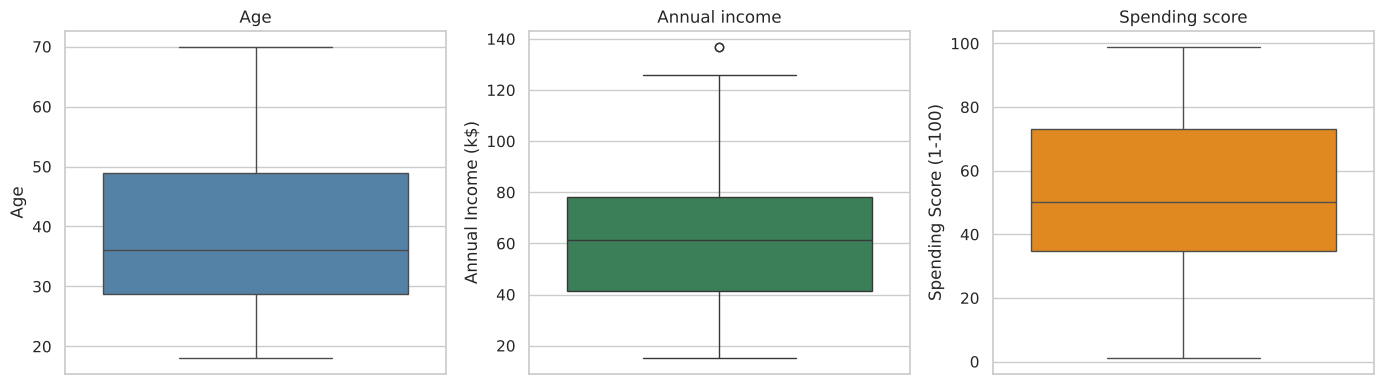

In [9]:
# One box plot for each number column
# Separate charts are used because age, income, and spending use different scales
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(y=df["Age"], ax=axes[0], color="steelblue")
axes[0].set_title("Age")
axes[0].set_ylabel("Age")

sns.boxplot(y=df["Annual Income (k$)"], ax=axes[1], color="seagreen")
axes[1].set_title("Annual income")
axes[1].set_ylabel("Annual Income (k$)")

sns.boxplot(y=df["Spending Score (1-100)"], ax=axes[2], color="darkorange")
axes[2].set_title("Spending score")
axes[2].set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.savefig("../outputs/02_boxplots.png", dpi=120)
plt.show()

**How to read these box plots**

- **Age:** the middle age is **36**. The box sits mostly between the high 20s and the high 40s. No age sits far outside the rest of the group.
- **Income:** the middle income is about **62**. Two customers earn **137**, which is higher than everyone else. They are still real customers, so we keep them.
- **Spending score:** the middle score is **50**. The box is wide, from about **35** to **73**. Customers really do spend in very different ways. No spending score sits far outside the main group.

### Correlation heatmap

Correlation tells us if two columns move together in a straight line.

- A number close to **1** means they rise together.
- A number close to **0** means there is no straight-line link.
- A negative number means one tends to go down when the other goes up.

In [10]:
# corr() compares each pair of number columns
# This creates a new small table. It does not change df.
correlation = df[number_columns].corr()
correlation

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


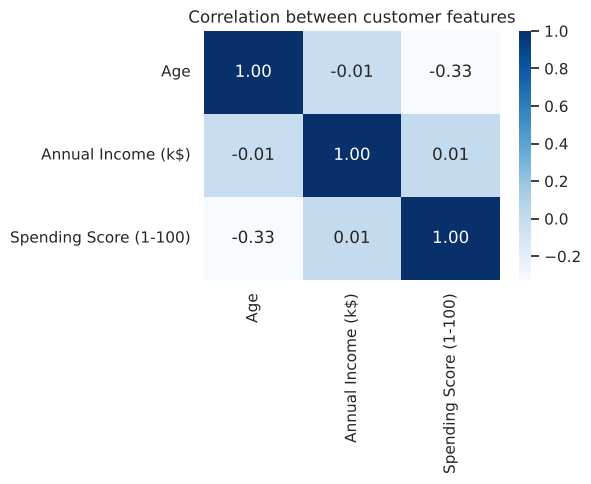

In [11]:
# Draw the correlation table as a colored grid
# annot=True prints the number inside each square
plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation between customer features")
plt.tight_layout()
plt.savefig("../outputs/03_correlation_heatmap.png", dpi=120)
plt.show()

**How to read this heatmap**

- **Age and income** are about **-0.01**. Age does not tell us how much a customer earns.
- **Income and spending score** are about **0.01**. A higher income does not automatically mean a higher spending score.
- **Age and spending score** are about **-0.33**. This is a weak link. Older customers tend to have a slightly lower spending score, but age does not decide spending by itself.

The useful business point is the second one: knowing income alone does not tell the shop who spends more. The next steps will use these numbers to place customers into groups.

## Step 4: Feature Selection

Feature selection is the process of choosing which columns to feed into our machine learning model.

In customer segmentation with K-Means clustering, our goal is to group customers based on their **demographics and shopping behavior**.

### 1. Features Excluded

- **`CustomerID`**:
  - `CustomerID` is simply a sequential label (1, 2, 3...) assigned when a record is created.
  - It has zero customer behavioral or economic meaning.
  - K-Means uses distance calculations (Euclidean distance). If we included `CustomerID`, the algorithm would cluster customers based on their arbitrary ID numbers instead of how they actually shop.
- **`Gender`**:
  - `Gender` is a categorical text feature (`Male` / `Female`).
  - Standard K-Means relies on mathematical distance between continuous numbers.
  - For this initial model, we focus on continuous numerical characteristics.

### 2. Features Selected

We select the following three features:

1. **`Age`**:
   - Represents the customer's life stage (e.g., college students, working professionals, retirees).
   - Shopping preferences and product interests often change with age.
2. **`Annual Income (k$)`**:
   - Represents the customer's financial capacity and spending power.
   - Tells the mall how much money the customer earns per year.
3. **`Spending Score (1-100)`**:
   - Represents actual customer purchasing behavior at the mall.
   - Assigned by the mall based on customer spending habits and visit frequency.

Combining demographic life stage (`Age`), purchasing power (`Annual Income`), and actual shopping habits (`Spending Score`) gives a comprehensive picture of each customer.

In [12]:
# Create feature matrix X with the three selected numerical features
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

# Display the first 5 rows of our selected features
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [13]:
# Check the shape of X (rows, columns)
print("Shape of feature matrix X:")
print(X.shape)

# Check the column names in X
print("\nColumns in X:")
print(X.columns.tolist())

Shape of feature matrix X:
(200, 3)

Columns in X:
['Age', 'Annual Income (k$)', 'Spending Score (1-100)']


### Summary of Feature Selection

- **Number of records:** 200 customers (all rows preserved).
- **Number of features:** 3 numerical features (`Age`, `Annual Income (k$)`, `Spending Score (1-100)`).
- **Excluded columns:** `CustomerID` (arbitrary ID) and `Gender` (categorical text).

Our feature matrix `X` is now prepared. In **Step 5**, we will examine why these features require scaling before clustering.

## Step 5: Feature Scaling using StandardScaler

### Why is Feature Scaling Important for K-Means?

K-Means is a **distance-based algorithm**. It groups customers by calculating the straight-line (Euclidean) distance between points:

$$\text{Distance} = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2 + (z_1 - z_2)^2}$$

In our raw data, our three features have very different ranges:
- **`Age`**: ranges from 18 to 70 (spread of ~52).
- **`Annual Income (k$)`**: ranges from 15 to 137 (spread of ~122).
- **`Spending Score (1-100)`**: ranges from 1 to 99 (spread of ~98).

If we do not scale the features, `Annual Income` has the largest numbers and the largest variance. A difference of \$50,000 in income would completely overpower a difference of 20 years in age. The algorithm would group customers almost entirely by income and ignore age.

**Feature scaling puts all features onto the same playing field so each feature contributes equally to the distance calculation.**

---

### What is StandardScaler?

`StandardScaler` standardizes each feature using this simple formula:

$$z = \frac{x - \mu}{\sigma}$$

- **$x$**: The original value.
- **$\mu$ (Mean)**: The average of all values in that column.
- **$\sigma$ (Standard Deviation)**: How spread out the values are.
- **$z$ (Z-Score)**: The new scaled value.

After scaling:
- The **mean (average)** of each feature becomes **0**.
- The **standard deviation (spread)** becomes **1**.
- A value of **0** means exactly average.
- A **positive value** means above average.
- A **negative value** means below average.

---

### What does `fit_transform()` do?

`fit_transform()` performs two actions in one step:
1. **`fit()`**: Learns the mean ($\mu$) and standard deviation ($\sigma$) from our data `X`.
2. **`transform()`**: Applies the formula $z = \frac{x - \mu}{\sigma}$ to convert all values in `X` into scaled values.

In [14]:
# Import StandardScaler from Scikit-learn
from sklearn.preprocessing import StandardScaler

# Create the StandardScaler object
scaler = StandardScaler()

# Fit to the data and transform X into scaled values
X_scaled = scaler.fit_transform(X)

# Convert the scaled array into a Pandas DataFrame with original column names
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Display the first 5 rows of scaled data
X_scaled_df.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


In [15]:
# Display the mean of each scaled feature (target is 0)
# Note: Numbers like 1e-16 are scientific notation for 0.0000000000000001, effectively 0
print("Mean of scaled features (rounded to 2 decimals):")
print(X_scaled_df.mean().round(2))

# Display the standard deviation of each scaled feature (target is 1)
print("\nStandard deviation of scaled features (rounded to 2 decimals):")
print(X_scaled_df.std().round(2))

Mean of scaled features (rounded to 2 decimals):
Age                      -0.0
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standard deviation of scaled features (rounded to 2 decimals):
Age                       1.0
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


### What the Scaled Results Tell Us

1. **Mean is 0.00**: Every feature is now centered around zero.
2. **Standard Deviation is 1.00**: Every feature has the exact same spread.
3. **No feature will dominate**: Age, Annual Income, and Spending Score now have equal weight when K-Means calculates distances.

For example, looking at the first customer (Row 0):
- `Age` = **-1.42** (younger than the average customer).
- `Annual Income` = **-1.74** (earns significantly less than the average customer).
- `Spending Score` = **-0.43** (spends slightly below average).

Our data is now properly prepared for **Step 6: K-Means Clustering**.

## Step 6: K-Means Clustering using the Elbow Method

### What is K-Means Clustering?

K-Means is an **unsupervised machine learning algorithm** that groups unlabelled data into **$K$ distinct clusters**.

How K-Means works step-by-step:
1. **Choose $K$**: We specify how many groups we want to find (e.g., $K=4$ or $K=5$).
2. **Initialize Centroids**: The algorithm places $K$ center points (called **centroids**) in the feature space.
3. **Assign Points**: Every customer is assigned to their nearest centroid based on straight-line (Euclidean) distance.
4. **Update Centroids**: The algorithm calculates the mean of all points assigned to each cluster and relocates the centroid to this new mean.
5. **Repeat**: Steps 3 and 4 repeat until the centroids stop changing position (convergence).

---

### What is Inertia and WCSS?

- **WCSS (Within-Cluster Sum of Squares)**: Measures how tight and compact each cluster is. For every customer, we take the squared distance to their cluster centroid and sum them all up:
  $$\text{WCSS} = \sum_{i=1}^{n} (x_i - c_k)^2$$
- **Inertia**: In Scikit-learn, WCSS is stored in the `.inertia_` attribute.
  - **Lower inertia** means tighter, more compact clusters.
  - When $K=1$, inertia is at its highest (all 200 customers in 1 giant cluster).
  - When $K=200$, inertia is 0 (every customer is their own cluster, which has no business value).

---

### What is the Elbow Method?

The **Elbow Method** finds the optimal balance between cluster compactness and model simplicity.

- We fit K-Means for $K = 1, 2, 3, \dots, 10$ and record the inertia for each $K$.
- As $K$ increases, inertia always decreases.
- Early on ($K=1 \to K=4$), adding clusters causes large drops in inertia.
- At a certain point, the rate of decrease slows down dramatically, forming a visible **"elbow"** shape on the curve.
- The point where the curve bends is chosen as the **optimal $K$**, because adding more clusters beyond that point gives diminishing returns.

In [16]:
# Import KMeans from Scikit-learn
from sklearn.cluster import KMeans

# Calculate inertia (WCSS) for K values from 1 to 10
wcss = []
k_values = range(1, 11)

for k in k_values:
    # random_state=42 ensures identical, reproducible results
    # n_init=10 runs the algorithm 10 times with different starting centroids to pick the best one
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    print(f"K = {k:2d} -> Inertia (WCSS) = {kmeans.inertia_:.2f}")

K =  1 -> Inertia (WCSS) = 600.00
K =  2 -> Inertia (WCSS) = 389.39
K =  3 -> Inertia (WCSS) = 295.21
K =  4 -> Inertia (WCSS) = 205.23
K =  5 -> Inertia (WCSS) = 168.25
K =  6 -> Inertia (WCSS) = 133.87
K =  7 -> Inertia (WCSS) = 117.01
K =  8 -> Inertia (WCSS) = 103.87
K =  9 -> Inertia (WCSS) = 93.09
K = 10 -> Inertia (WCSS) = 82.39


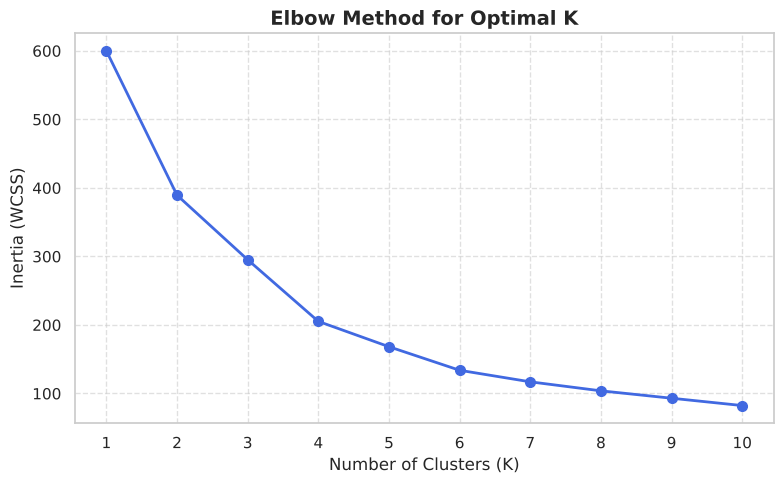

In [17]:
# Create the Elbow Method plot using Matplotlib
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker="o", color="royalblue", linewidth=2, markersize=7)

plt.title("Elbow Method for Optimal K", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("Inertia (WCSS)", fontsize=12)
plt.xticks(list(k_values))
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

# Save the elbow curve plot into outputs/
plt.savefig("../outputs/04_elbow_method.png", dpi=120)
plt.show()

### Analysis of the Elbow Curve

Let us analyze the drop in inertia for each additional cluster:

| K | Inertia (WCSS) | Drop from Previous K | Rate of Reduction |
| :-: | :-: | :-: | :--- |
| **1** | 600.00 | — | Baseline |
| **2** | 389.39 | **210.61** | Very sharp reduction |
| **3** | 295.21 | **94.18** | Sharp reduction |
| **4** | 205.23 | **89.98** | Sharp reduction (curve starts to bend) |
| **5** | 168.25 | **36.98** | Clear slowdown |
| **6** | 133.87 | **34.38** | Moderate reduction |
| **7** | 117.01 | **16.86** | Curve flattens |
| **8** | 103.87 | **13.14** | Diminishing returns |
| **9** | 93.09 | **10.78** | Diminishing returns |
| **10** | 82.39 | **10.70** | Diminishing returns |

#### Observations:
1. **The elbow is gradual, not sharp.** The curve visibly bends around K = 4. The biggest slowdown happens when going from K = 4 to K = 5 (the drop falls from about 90 to about 37). From K = 7 onwards, each extra cluster reduces inertia by fewer than 17 points. So the elbow points to a *range* of K = 4 to 6, not one exact value.
2. **Business actionability:** K = 5 gives five clearly different personas (High Income / High Spenders, High Income / Low Spenders, Low Income / High Spenders, Low Income / Low Spenders, and Moderate Spenders).
3. Because the elbow is not decisive, we also check the **Silhouette Score** below before choosing K.

### Silhouette Score check

The Silhouette Score measures how well each customer fits its own cluster compared with the nearest other cluster. It ranges from -1 to 1, and **higher is better**. It needs at least 2 clusters, so we test K = 2 to 10.

In [18]:
# Silhouette score for K = 2 to 10 (same settings as the elbow loop)
from sklearn.metrics import silhouette_score

sil_k_values = list(range(2, 11))
sil_scores = []

for k in sil_k_values:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"K = {k:2d} -> Silhouette score = {score:.4f}")

best_k = sil_k_values[sil_scores.index(max(sil_scores))]
print(f"\nHighest silhouette score: K = {best_k} ({max(sil_scores):.4f})")

K =  2 -> Silhouette score = 0.3355
K =  3 -> Silhouette score = 0.3578
K =  4 -> Silhouette score = 0.4040
K =  5 -> Silhouette score = 0.4166
K =  6 -> Silhouette score = 0.4284
K =  7 -> Silhouette score = 0.4172
K =  8 -> Silhouette score = 0.4082
K =  9 -> Silhouette score = 0.4177
K = 10 -> Silhouette score = 0.4066

Highest silhouette score: K = 6 (0.4284)


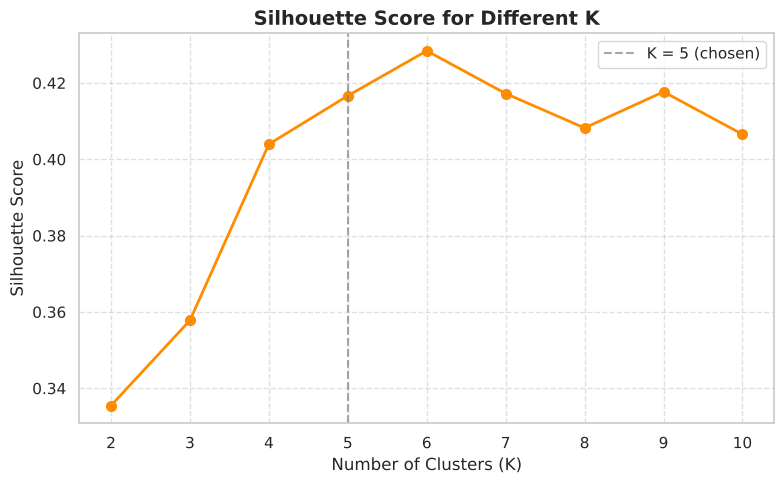

In [19]:
# Plot the silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(sil_k_values, sil_scores, marker="o", color="darkorange", linewidth=2, markersize=7)
plt.axvline(5, color="gray", linestyle="--", alpha=0.7, label="K = 5 (chosen)")

plt.title("Silhouette Score for Different K", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.xticks(sil_k_values)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("../outputs/07_silhouette_scores.png", dpi=120)
plt.show()

### Reading the silhouette scores and choosing K

- **K = 5** scores **0.4166** and **K = 4** scores **0.4040**.
- The **highest** score is at **K = 6** (**0.4284**), so silhouette alone does *not* pick K = 5.
- For K = 4 to 10 all scores lie between about 0.40 and 0.43. Silhouette does not strongly prefer any one K in this range. Values around 0.4 mean the clusters have reasonable structure but are not sharply separated.

**Decision:** we use **K = 5**. It sits inside the elbow range (K = 4 to 6), its silhouette score is close to the best, and it gives five personas that are easy to describe and act on. K = 6 would be a reasonable alternative to test in future work.

## Step 7: Cluster Analysis & Customer Profiling

The Elbow Method (bend around K = 4 to 6) and the Silhouette scores (similar for K = 4 to 10) do not point to one single best K. We choose **K = 5** because it sits inside the elbow range, its silhouette score (0.4166) is close to the best (0.4284 at K = 6), and it gives five business personas that are easy to describe and act on. We now fit the final K-Means model.

### Steps in this section:
1. Fit the final K-Means model with K = 5.
2. Assign each of the 200 customers to a cluster (0, 1, 2, 3, or 4).
3. Calculate the average Age, Annual Income, and Spending Score for each group.
4. Translate the numbers into real-world business personas with targeted marketing strategies.

In [20]:
# Fit the final K-Means model with K=5 clusters
kmeans_final = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)

# Predict cluster labels for each customer
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to our working dataframe
df_clustered = df.copy()
df_clustered["Cluster"] = cluster_labels

# Display the first 5 rows with the assigned Cluster column
df_clustered.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1


In [21]:
# Count how many customers belong to each cluster
print("Customer count per cluster:")
print(df_clustered["Cluster"].value_counts().sort_index())

# Calculate the average values for each cluster
cluster_profile = df_clustered.groupby("Cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(2)
print("\nCluster profile (Average values):")
display(cluster_profile)

Customer count per cluster:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64

Cluster profile (Average values):


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,46.25,26.75,18.35
1,25.19,41.09,62.24
2,32.88,86.10,81.53
3,39.87,86.10,19.36
4,55.64,54.38,48.85


In [22]:
# Detailed breakdown showing min, median, and max for each cluster
for cluster_id in range(5):
    sub = df_clustered[df_clustered["Cluster"] == cluster_id]
    print(f"=== Cluster {cluster_id} (Count: {len(sub)} customers) ===")
    print(f"Age: Min = {sub['Age'].min()}, Median = {sub['Age'].median():.0f}, Max = {sub['Age'].max()}, Mean = {sub['Age'].mean():.1f}")
    print(f"Income ($k): Min = {sub['Annual Income (k$)'].min()}, Median = {sub['Annual Income (k$)'].median():.0f}, Max = {sub['Annual Income (k$)'].max()}, Mean = {sub['Annual Income (k$)'].mean():.1f}")
    print(f"Spending Score: Min = {sub['Spending Score (1-100)'].min()}, Median = {sub['Spending Score (1-100)'].median():.0f}, Max = {sub['Spending Score (1-100)'].max()}, Mean = {sub['Spending Score (1-100)'].mean():.1f}\n")

=== Cluster 0 (Count: 20 customers) ===
Age: Min = 20, Median = 47, Max = 67, Mean = 46.2
Income ($k): Min = 16, Median = 26, Max = 39, Mean = 26.8
Spending Score: Min = 3, Median = 14, Max = 36, Mean = 18.4

=== Cluster 1 (Count: 54 customers) ===
Age: Min = 18, Median = 24, Max = 38, Mean = 25.2
Income ($k): Min = 15, Median = 40, Max = 67, Mean = 41.1
Spending Score: Min = 39, Median = 58, Max = 99, Mean = 62.2

=== Cluster 2 (Count: 40 customers) ===
Age: Min = 27, Median = 32, Max = 40, Mean = 32.9
Income ($k): Min = 69, Median = 78, Max = 137, Mean = 86.1
Spending Score: Min = 58, Median = 83, Max = 97, Mean = 81.5

=== Cluster 3 (Count: 39 customers) ===
Age: Min = 19, Median = 41, Max = 59, Mean = 39.9
Income ($k): Min = 64, Median = 78, Max = 137, Mean = 86.1
Spending Score: Min = 1, Median = 17, Max = 42, Mean = 19.4

=== Cluster 4 (Count: 47 customers) ===
Age: Min = 40, Median = 54, Max = 70, Mean = 55.6
Income ($k): Min = 38, Median = 54, Max = 79, Mean = 54.4
Spending Sco

### Business Personas & Marketing Strategies

Based on the actual cluster averages and ranges, we identify 5 distinct customer groups:

| Cluster | Customer Count | Avg Age | Avg Income | Avg Spending | Business Persona | Core Characteristics |
| :---: | :---: | :---: | :---: | :---: | :--- | :--- |
| **0** | **20** | **46.2** | **$26.8k** | **18.4** | **Sensible / Budget Shoppers** | Mature customers with low income and low spending. Likely price-conscious. |
| **1** | **54** | **25.2** | **$41.1k** | **62.2** | **Young Trendsetters / Enthusiasts** | Youngest group with moderate income but high willingness to spend on fashion, dining, and lifestyle. |
| **2** | **40** | **32.9** | **$86.1k** | **81.5** | **Affluent VIP Shoppers** | Young-to-middle working adults with high income and top-tier spending. Highest spending score of all groups. |
| **3** | **39** | **39.9** | **$86.1k** | **19.4** | **Careful Affluent / Savers** | High-earning customers who spend very little at the mall. Potential to grow their spending. |
| **4** | **47** | **55.6** | **$54.4k** | **48.9** | **Steady Traditionalists** | Older demographic with stable income and consistent, moderate spending habits. |

---

### Actionable Marketing Recommendations:

1. **Cluster 0 (Sensible / Budget Shoppers):**
   - *Strategy:* Value-driven promotions, discount coupons, clearance sales, and budget-friendly product displays.
2. **Cluster 1 (Young Trendsetters / Enthusiasts):**
   - *Strategy:* Social media campaigns, youth fashion promotions, student discounts, experiential events, and trendy food court partnerships.
3. **Cluster 2 (Affluent VIP Shoppers):**
   - *Strategy:* Premium luxury brand offerings, VIP concierge access, exclusive loyalty rewards, private previews, and personalized shopping services.
4. **Cluster 3 (Careful Affluent / Savers):**
   - *Strategy:* High-quality, durable investment goods, exclusive invitations, premium dining, and service guarantees to incentivize wallet-share from their high income.
5. **Cluster 4 (Steady Traditionalists):**
   - *Strategy:* Reliable customer service, straightforward loyalty perks, quality assurance, family-oriented promotions, and pleasant physical store accessibility.

We are now ready for **Step 8: Visualization** (creating 2D and multi-dimensional scatter plots of these clusters).

## Step 8: Cluster Visualizations

Now that every customer has been assigned to one of 5 clusters, we create scatter plots to **see the groups visually**.

A scatter plot places each customer as a dot on a 2D grid. We pick two features for the axes and colour each dot by its cluster number. When the clusters are well-separated, customers of the same colour will naturally appear close together as islands on the chart.

We create two separate plots:
1. **Annual Income vs Spending Score** — shows the financial behaviour pattern.
2. **Age vs Spending Score** — shows how spending habits relate to age.

A fixed colour is used for each cluster across both charts so they are easy to compare side by side:
- Cluster 0 → Red
- Cluster 1 → Green
- Cluster 2 → Blue
- Cluster 3 → Orange
- Cluster 4 → Purple

In [23]:
# Define cluster colours and persona labels used in every chart
cluster_colors = {0: "red", 1: "green", 2: "blue", 3: "orange", 4: "purple"}
cluster_labels_map = {
    0: "Cluster 0: Budget Shoppers",
    1: "Cluster 1: Young Trendsetters",
    2: "Cluster 2: Affluent VIPs",
    3: "Cluster 3: Careful Affluents",
    4: "Cluster 4: Steady Traditionalists"
}
print("Colour map and persona labels ready.")

Colour map and persona labels ready.


Chart saved to outputs/05_clusters_income_vs_spending.png


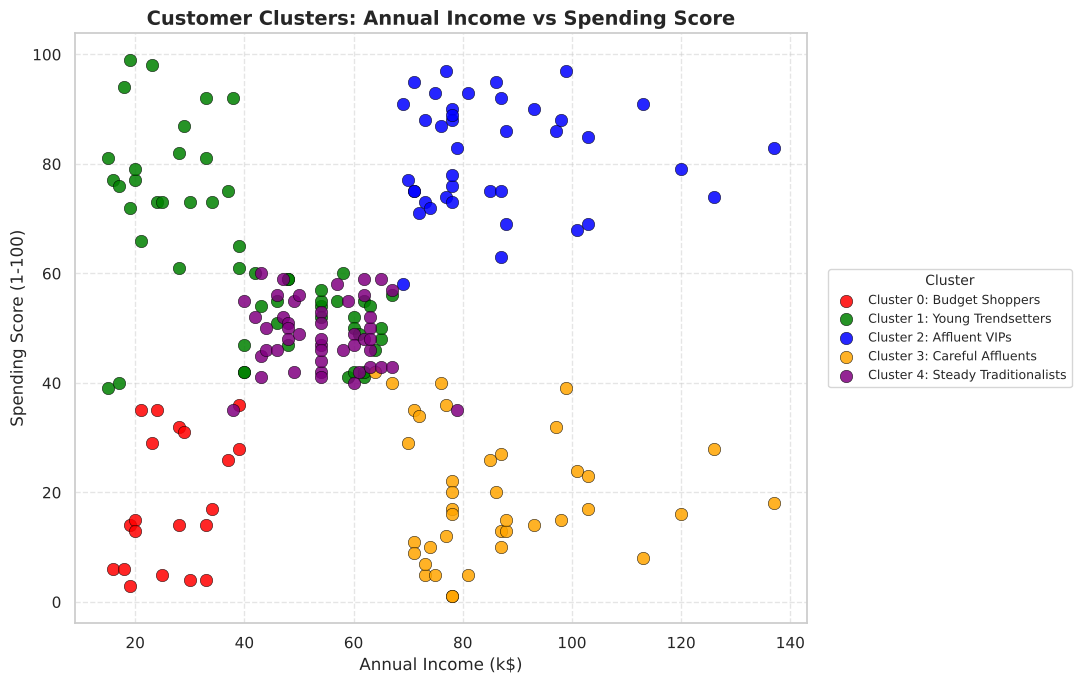

In [24]:
# ── Plot 1: Annual Income vs Spending Score ──────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 7))

for cluster_id in range(5):
    subset = df_clustered[df_clustered["Cluster"] == cluster_id]
    ax.scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        c=cluster_colors[cluster_id],
        label=cluster_labels_map[cluster_id],
        s=80,            # dot size
        alpha=0.85,      # slight transparency so overlapping dots are visible
        edgecolors="black",
        linewidths=0.4
    )

ax.set_title("Customer Clusters: Annual Income vs Spending Score", fontsize=14, fontweight="bold")
ax.set_xlabel("Annual Income (k$)", fontsize=12)
ax.set_ylabel("Spending Score (1-100)", fontsize=12)
ax.legend(title="Cluster", fontsize=9, title_fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5))  # legend outside the plot so it hides no dots
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../outputs/05_clusters_income_vs_spending.png", dpi=120, bbox_inches="tight")
plt.show()
print("Chart saved to outputs/05_clusters_income_vs_spending.png")

**How to read this chart**

Each dot is one customer. The horizontal axis shows how much the customer earns per year. The vertical axis shows how much they spend at the mall (the spending score).

- **Blue dots (Cluster 2 – Affluent VIPs):** Top-right corner. High income *and* high spending. These are the highest-spending, high-income customers.
- **Orange dots (Cluster 3 – Careful Affluents):** Bottom-right corner. High income but very low spending. Room to grow spending.
- **Green dots (Cluster 1 – Young Trendsetters):** Left side, upper area. Moderate income but high spending enthusiasm.
- **Red dots (Cluster 0 – Budget Shoppers):** Bottom-left. Low income and low spending.
- **Purple dots (Cluster 4 – Steady Traditionalists):** Centre of the chart. Average income and average spending.

Four clusters sit in clear corners. **Clusters 1 (green) and 4 (purple) overlap in the centre** of this 2D view. That is expected, because K-Means also used Age (a third feature) and the two groups differ strongly by age (young vs older), as the next chart shows.

Chart saved to outputs/06_clusters_age_vs_spending.png


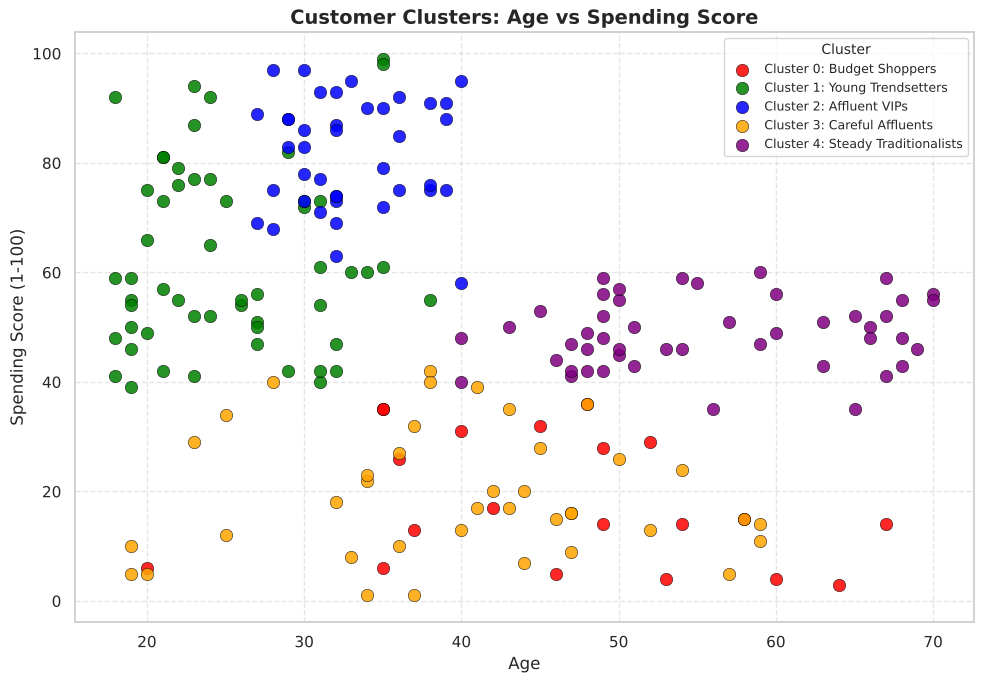

In [25]:
# ── Plot 2: Age vs Spending Score ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for cluster_id in range(5):
    subset = df_clustered[df_clustered["Cluster"] == cluster_id]
    ax.scatter(
        subset["Age"],
        subset["Spending Score (1-100)"],
        c=cluster_colors[cluster_id],
        label=cluster_labels_map[cluster_id],
        s=80,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.4
    )

ax.set_title("Customer Clusters: Age vs Spending Score", fontsize=14, fontweight="bold")
ax.set_xlabel("Age", fontsize=12)
ax.set_ylabel("Spending Score (1-100)", fontsize=12)
ax.legend(title="Cluster", fontsize=9, title_fontsize=10, loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../outputs/06_clusters_age_vs_spending.png", dpi=120)
plt.show()
print("Chart saved to outputs/06_clusters_age_vs_spending.png")

**How to read this chart**

The horizontal axis is the customer's age. The vertical axis is again the spending score.

- **Green dots (Cluster 1 – Young Trendsetters):** Packed tightly on the left (ages 18–38) in the upper half. Younger customers in this group spend actively despite moderate incomes.
- **Blue dots (Cluster 2 – Affluent VIPs):** Also young-to-middle (27–40) but form a distinct upper band because their income is much higher.
- **Purple dots (Cluster 4 – Steady Traditionalists):** Spread across the right side (ages 40–70) in the middle spending range. Older but steady.
- **Red dots (Cluster 0 – Budget Shoppers):** Scattered across various ages in the bottom portion. Low spending regardless of age.
- **Orange dots (Cluster 3 – Careful Affluents):** Also at the bottom but their ages are spread across about 19–59. High earners who do not spend.

This chart highlights the EDA finding from Step 3: **age and spending have only a weak correlation (-0.33).** The clusters explain the hidden structure — it is not purely age that drives spending, it is the combination of age, income, and spending habits together.

### Step 8 Summary

| Output File | Description |
| :--- | :--- |
| `outputs/05_clusters_income_vs_spending.png` | Annual Income vs Spending Score — 5 colour-coded clusters |
| `outputs/06_clusters_age_vs_spending.png` | Age vs Spending Score — 5 colour-coded clusters |

Together, the two charts show how the clusters separate. In the income vs spending chart, four clusters sit in clear corners while Clusters 1 and 4 overlap in the centre. Age (the third feature) is what separates those two: Cluster 1 is young and Cluster 4 is older.

We are now ready for the final step: **Step 9 — Conclusion, business applications, and portfolio summary.**

---

## Step 9: Final Conclusion & Portfolio Documentation

This section summarises the entire project: what was done, what was found, and what the results mean for the business.

### 9A. Project Overview

| Field | Details |
| :--- | :--- |
| **Project Title** | Customer Segmentation using Machine Learning |
| **Algorithm** | K-Means Clustering (Unsupervised Learning) |
| **Dataset** | Mall_Customers.csv |
| **Records** | 200 customers |
| **Features used** | Age, Annual Income (k$), Spending Score (1-100) |
| **Chosen Number of Clusters** | K = 5 (elbow range 4–6; see Step 6) |
| **Silhouette Score** | 0.4166 |

**Business Problem:**
A shopping mall wants to understand its customers better so it can send the right promotions to the right people. Currently, every customer receives the same marketing message, which wastes money on customers who are unlikely to respond.

**Project Objective:**
Use K-Means Clustering to automatically group 200 customers into distinct segments based on their age, annual income, and spending score — without any pre-existing labels — so the marketing team can personalise campaigns for each group.

**Dataset Description:**
The dataset contains demographic and behavioural information for 200 mall customers:
- `CustomerID` — unique identifier (not used in modelling)
- `Gender` — Male or Female (not used in this initial model)
- `Age` — customer age in years (18–70)
- `Annual Income (k$)` — yearly income in thousands of dollars (15–137)
- `Spending Score (1–100)` — a score assigned by the mall reflecting spending habits and visit frequency

### 9B. Tools and Technologies Used

| Technology | Purpose |
| :--- | :--- |
| **Python 3** | Core programming language |
| **Pandas** | Data loading, inspection, cleaning, and profiling |
| **NumPy** | Underlying numerical operations (used implicitly via Pandas and Scikit-learn) |
| **Matplotlib** | Building all charts (histograms, box plots, elbow curve, scatter plots) |
| **Seaborn** | Box plots and correlation heatmap (built on Matplotlib) |
| **Scikit-learn** | `StandardScaler` for feature scaling; `KMeans` for clustering |
| **Jupyter Notebook** | Interactive, step-by-step notebook environment |

> **Note:** No deep learning libraries (TensorFlow, PyTorch, Keras) were used. No external datasets were downloaded. All results come from the original `Mall_Customers.csv` file.

### 9C. Complete Project Workflow

**Step 1 — Dataset Loading**
Loaded `Mall_Customers.csv` using `pd.read_csv()` and confirmed the dataset with `df.head()`. The file already existed on the system; no data was downloaded or created.

**Step 2 — Data Cleaning**
Verified the shape `(200, 5)`, inspected data types, and confirmed:
- **0 missing values** across all 5 columns.
- **0 duplicate rows**.
- **200 unique CustomerIDs** — every record is a distinct customer.
No rows were modified or removed. The original CSV was not changed.

**Step 3 — Exploratory Data Analysis (EDA)**
Computed descriptive statistics (`df.describe()`) and produced three saved charts:
- `01_histograms.png` — distribution of Age, Annual Income, and Spending Score.
- `02_boxplots.png` — spread, medians, and extreme values per feature.
- `03_correlation_heatmap.png` — revealed a near-zero correlation (0.01) between Annual Income and Spending Score, the key motivation for clustering.

**Step 4 — Feature Selection**
Created feature matrix `X` by selecting three continuous numerical columns:
- `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.
- Excluded `CustomerID` (arbitrary sequential label with no behavioural meaning).
- Excluded `Gender` (categorical text; not suitable for standard K-Means distance calculations).

**Step 5 — Feature Scaling**
Applied `StandardScaler` to transform all features to mean = 0 and standard deviation = 1. This step is essential because K-Means uses Euclidean distance — without scaling, Annual Income (range: 15–137) would dominate distance calculations over Age (range: 18–70), producing biased clusters.

**Step 6 — K-Means Clustering using the Elbow Method**
Fitted K-Means for K = 1 to K = 10 and recorded the inertia (WCSS) at each step. The elbow is gradual: the curve bends around K = 4, with the biggest slowdown from K = 4 to K = 5 (drop falls from ~90 to ~37). Silhouette scores for K = 2 to 10 were also computed (K = 5: 0.4166, K = 4: 0.4040, highest at K = 6: 0.4284), so neither method gives one exact K. K = 5 was chosen as a balance of elbow position, silhouette score, and interpretable personas. Saved `04_elbow_method.png` and `07_silhouette_scores.png`.

**Step 7 — Cluster Analysis and Customer Profiling**
Fitted the final K-Means model with K = 5 and assigned cluster labels (0–4) to all 200 customers. Computed average Age, Income, and Spending Score per cluster. Translated each cluster into a named business persona with a targeted marketing strategy.

**Step 8 — Cluster Visualizations**
Produced two colour-coded scatter plots:
- `05_clusters_income_vs_spending.png` — the primary chart; reveals four clean corner clusters plus a central group.
- `06_clusters_age_vs_spending.png` — shows cluster separation across age; clusters overlap more here because Age has weaker correlation with Spending than Income does.

**Step 9 — Conclusion (this section)**
Summarised all findings, documented the technical decisions, and prepared the project for a Data Science portfolio.

### 9D. Final Customer Segments (Verified Results)

The following profiles are based on the actual K-Means output stored in `df_clustered`.

| Cluster | Persona | Count | Avg Age | Avg Income | Avg Spending |
| :---: | :--- | :---: | :---: | :---: | :---: |
| **0** | Sensible Budget Shoppers | 20 | 46.2 | \$26.8k | 18.4 |
| **1** | Young Trendsetters / Enthusiasts | 54 | 25.2 | \$41.1k | 62.2 |
| **2** | Affluent VIP Shoppers | 40 | 32.9 | \$86.1k | 81.5 |
| **3** | Careful Affluent / Savers | 39 | 39.9 | \$86.1k | 19.4 |
| **4** | Steady Traditionalists | 47 | 55.6 | \$54.4k | 48.9 |

---

**Cluster 0 — Sensible Budget Shoppers (20 customers)**
Mature customers with low income and very low spending. The smallest group. They are likely price-sensitive (the dataset has no visit-frequency data, so this is an interpretation).
*Marketing approach:* Discount programmes, clearance events, loyalty rewards for repeat small purchases.

**Cluster 1 — Young Trendsetters / Enthusiasts (54 customers — largest group)**
The youngest segment, with moderate income but above-average spending enthusiasm. They spend proportionally more than their income suggests. Social proof, trends, and experiences drive their purchases.
*Marketing approach:* Social media campaigns, flash sales, lifestyle brand partnerships, food court and entertainment events.

**Cluster 2 — Affluent VIP Shoppers (40 customers)**
Young-to-middle working adults with the highest income and the highest spending score. This segment has the highest spending scores.
*Marketing approach:* Premium brand activations, VIP membership programmes, personalised concierge shopping, exclusive early access to collections.

**Cluster 3 — Careful Affluent / Savers (39 customers)**
Share the same income level as Cluster 2 (\$86.1k average) but have one of the lowest spending scores (19.4). A potentially large opportunity: these customers have the financial capacity to spend, but their spending scores are low. The data does not tell us why.
*Marketing approach:* High-quality, durable goods positioning; premium dining experiences; service and warranty guarantees; exclusive members-only events that appeal to value-consciousness rather than impulse.

**Cluster 4 — Steady Traditionalists (47 customers)**
The oldest group, with stable mid-range income and consistent, predictable moderate spending. They are habitual, loyal shoppers who value reliability over novelty.
*Marketing approach:* Straightforward loyalty programmes, comfortable in-store environments, family promotions, senior-friendly services.

### 9E. Key Business Insights

**Insight 1: High income does not mean high spending.**
Clusters 2 and 3 have identical average annual income (\$86.1k), yet their average spending scores are almost exact opposites (81.5 vs 19.4). A simple income-only analysis would treat these two groups identically, completely missing the \$86k-earning customers who barely spend at the mall.

**Insight 2: The highest-spending customers are young, affluent, and active.**
Cluster 2 (Affluent VIPs) — 40 customers earning above \$69k and scoring above 58 on spending — has the highest spending scores (note: spending score is a proxy for spending, not actual revenue). Retaining and rewarding them through VIP programmes is a sensible priority.

**Insight 3: A major growth opportunity may sit in Cluster 3.**
39 customers earning between \$64k and \$137k per year spend little at the mall (average score: 19.4). The data cannot explain why, but if targeted, value-driven campaigns can redirect even a portion of their spending to the mall, the uplift could be significant.

**Insight 4: Young customers spend more than their income would suggest.**
Cluster 1 (Young Trendsetters, ages 18–38) earns moderately (\$41.1k) but spends actively (score: 62.2). Their spending score is higher than that of older, wealthier Cluster 4 customers (\$54.4k income, score: 48.9). Youth-oriented content and experiences may drive a disproportionate share of spending.

**Insight 5: Customer segmentation enables efficient marketing spend.**
Without segmentation, the mall would send the same promotion to all 200 customers. With these 5 segments, the mall can run 5 tailored campaigns — VIP invitations for Cluster 2, discount vouchers for Cluster 0, social media influencer tie-ups for Cluster 1 — which should improve response rates and reduce wasted spend (to be validated with real campaign results).

### 9F. Technical Conclusion

**Why K-Means was selected:**
K-Means is a simple, interpretable, and computationally efficient unsupervised clustering algorithm. Because the goal is to discover natural groupings in unlabelled customer data — not to predict a known outcome — an unsupervised approach is correct. K-Means works directly with the continuous numerical features available in this dataset.

**Why K = 5 was selected:**
Neither method gives one exact answer, so K = 5 is a judgement call supported by evidence:
1. **Elbow Method (Inertia analysis):** The curve bends gradually around K = 4 to 6. The drop in inertia falls from about 90 (K = 3 to 4) to about 37 (K = 4 to 5), and from K = 7 onwards each extra cluster gains fewer than 17 points.
2. **Silhouette Score:** K = 5 scores 0.4166 (K = 4: 0.4040). The highest score is K = 6 (0.4284), but scores for K = 4 to 10 are all close (about 0.40 to 0.43).
3. **Interpretability:** K = 5 gives five distinct, easy-to-describe business personas.

**Why StandardScaler was necessary:**
K-Means uses Euclidean distance to assign customers to clusters. Without scaling:
- Annual Income spans ~122 units (15 to 137).
- Age spans ~52 units (18 to 70).
- Spending Score spans ~98 units (1 to 99).
A single-unit difference in Annual Income would carry more than twice the geometric weight of a single-unit difference in Age, biasing all cluster assignments toward income. StandardScaler brings every feature to mean = 0 and standard deviation = 1, so each feature contributes equally.

**Limitations of K-Means:**
1. **Assumes spherical clusters:** K-Means draws straight (linear) Voronoi boundaries — flat planes in 3D feature space. It cannot capture clusters with complex curved shapes.
2. **K must be specified in advance:** The algorithm does not automatically determine the optimal number of clusters. The Elbow Method and Silhouette analysis were used to guide this choice.
3. **Sensitive to initialisation:** Randomly placed starting centroids can lead to different solutions. This is mitigated by using `init="k-means++"` and `n_init=10` (10 independent runs, best result kept).
4. **Sensitive to outliers:** The two customers earning \$137k slightly pull the centroids of Clusters 2 and 3. StandardScaler reduces (but does not eliminate) this effect.
5. **Gender not used:** The initial model focuses on continuous numerical features. Gender differences in spending behaviour are not captured.

**Possible Future Improvements:**
1. Include `Gender` using binary encoding or separate gender-stratified models.
2. Apply DBSCAN or Gaussian Mixture Models (GMMs) to handle non-spherical cluster shapes.
3. Use PCA (Principal Component Analysis) to reduce the 3-dimensional feature space to 2D for cleaner visualisation.
4. Collect additional features (product category preferences, visit frequency, recency of purchase) for richer segmentation.
5. Deploy the trained scaler and model as a lightweight REST API or Streamlit app so the marketing team can classify new customers in real time.

### 9G. Final Project Summary

**What was built:**
A complete, end-to-end machine learning pipeline that takes raw, unlabelled mall customer data and produces 5 clearly defined, business-actionable customer segments using K-Means Clustering.

**What was found:**
- Customers cannot be described by a single average. K-Means found five groups with clearly different profiles (K = 5 is a modelling choice, not a proven true number of groups).
- High income does not guarantee high spending — the correlation between Annual Income and Spending Score is 0.01.
- K-Means with proper feature scaling (`StandardScaler`) finds five interpretable groups, with a moderate Silhouette Score of 0.4166 at K = 5.

**Output files produced:**
| File | Description |
| :--- | :--- |
| `outputs/01_histograms.png` | Distribution of Age, Income, Spending Score |
| `outputs/02_boxplots.png` | Spread and outliers for each feature |
| `outputs/03_correlation_heatmap.png` | Correlation matrix — key EDA finding |
| `outputs/04_elbow_method.png` | Inertia curve — visual basis for K = 5 |
| `outputs/05_clusters_income_vs_spending.png` | Primary cluster chart: 5 colour-coded groups |
| `outputs/06_clusters_age_vs_spending.png` | Secondary cluster chart: age dimension |

**Key takeaway for a Data Science interview:**
> *"I used K-Means Clustering on a 200-customer mall dataset. After scaling the features with StandardScaler, I used the Elbow Method and Silhouette analysis to narrow K to 4–6, and chose K = 5 because it gave the clearest business personas. The clusters revealed that high-income customers split into two opposite groups — big spenders and careful savers — a finding that would be completely invisible in a simple average or linear regression. The insights directly support targeted marketing campaigns for each of the five customer personas."*

---
*Project completed. Notebook contains 60 cells. All 9 steps are documented, executed, and verified.*

In [26]:
# Final verification: confirm all key numbers used in Step 9 conclusion
print("=" * 55)
print("  FINAL PROJECT VERIFICATION SUMMARY")
print("=" * 55)

print(f"\nDataset rows: {df.shape[0]}, columns: {df.shape[1]}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Unique CustomerIDs: {df['CustomerID'].nunique()}")

print(f"\nFeature matrix X shape: {X.shape}")
print(f"X_scaled mean (should be ~0): {X_scaled_df.mean().round(2).tolist()}")
print(f"X_scaled std  (should be  1): {X_scaled_df.std().round(2).tolist()}")

print(f"\nFinal K-Means: K = {kmeans_final.n_clusters}, Inertia = {kmeans_final.inertia_:.2f}")

print("\nCluster sizes:")
print(df_clustered['Cluster'].value_counts().sort_index().to_string())

print("\nCluster profiles (mean values):")
profile = df_clustered.groupby('Cluster')[['Age','Annual Income (k$)','Spending Score (1-100)']].mean().round(2)
print(profile.to_string())

print(f"\nSilhouette score (K=5): {silhouette_score(X_scaled, cluster_labels):.4f}")
print("\nAll 200 customers accounted for:", df_clustered.shape[0] == 200)
print("=" * 55)
print("  ALL STEPS COMPLETE — PROJECT READY FOR PORTFOLIO")
print("=" * 55)

  FINAL PROJECT VERIFICATION SUMMARY

Dataset rows: 200, columns: 5
Missing values: 0
Duplicate rows: 0
Unique CustomerIDs: 200

Feature matrix X shape: (200, 3)
X_scaled mean (should be ~0): [-0.0, -0.0, -0.0]
X_scaled std  (should be  1): [1.0, 1.0, 1.0]

Final K-Means: K = 5, Inertia = 168.25

Cluster sizes:
Cluster
0    20
1    54
2    40
3    39
4    47

Cluster profiles (mean values):
           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        46.25               26.75                   18.35
1        25.19               41.09                   62.24
2        32.88               86.10                   81.53
3        39.87               86.10                   19.36
4        55.64               54.38                   48.85

Silhouette score (K=5): 0.4166

All 200 customers accounted for: True
  ALL STEPS COMPLETE — PROJECT READY FOR PORTFOLIO
